# Spectra with Custom Initial States

So far, products of coherent states have been used as the initial states to observe the peaks. In practical spectrum calculations, however, the initial state is not always so simple, and users may want to use their own initial states.

In the SC-IVR calculation, the propagation of the trajectories and the calculation of the spectrum are independent: the initial state $|\Psi\rangle$ enters only through the overlap with the coherent states along the trajectories, $\langle \Psi | q_t, p_t \rangle$. Therefore, by defining the overlap, users can compute the dynamics of various initial states with the same trajectories, prefactors and actions. In a previous study, this property was used to compute accurate IR spectra by the semiclassical propagation of matrix product state (MPS) wave functions [1].

In this tutorial, the DVR eigenfunctions obtained in the tutorial *Pyramidal Inversion Spectrum of Ammonia* are used as the initial states, and we examine whether the corresponding eigenenergies are reproduced.

**References**

[1] M. Tsumura and Y. Kurashige, "On-The-Fly Dynamics of Multiconfigurational Wave Packets by a Semiclassical Method," *J. Chem. Theory Comput.* **21**, 11401-11414 (2025).

In [1]:
# import necessary libraries

import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize_scalar
import time

from pyscf import gto, dft
from pyscf.geomopt import berny_solver

from pyscivr.basis import get_overlap
from pyscivr.coordinates import InternalCoordinates, get_bond_angle, rigid_scan_1d
from pyscivr.integrators import ImplicitVerlet
from pyscivr.potentials import DFTPotential
from pyscivr.scivr import get_action, get_lagrangian, get_prefactor, get_ta_spectrum_fft
from pyscivr.units import CmInv, FemtoSec, HBar
from pyscivr.utils import get_geom
from pyscivr.variations import make_vari_propagator_implicit, propagate_variation_implicit

## System and coordinates

In [2]:
OOP_SCAN = np.array([0.5235987756, 0.5958192964, 0.6680398171, 0.7402603379, 0.8124808587, 0.8847013795,
                     0.9569219002, 1.029142421 , 1.1013629418, 1.1735834625, 1.2458039833, 1.3180245041,
                     1.3902450249, 1.4624655456, 1.5346860664, 1.6069065872, 1.679127108 , 1.7513476287,
                     1.8235681495, 1.8957886703, 1.968009191 , 2.0402297118, 2.1124502326, 2.1846707534,
                     2.2568912741, 2.3291117949, 2.4013323157, 2.4735528364, 2.5457733572, 2.617993878 ])
POT_EQ = -1539.7748000136369
POT = np.array([-1533.3679150656, -1535.1978467492, -1536.5575481381, -1537.5803862589, -1538.345944936 , -1538.9100711545,
                -1539.3104632371, -1539.5718410517, -1539.7174374798, -1539.772203703 , -1539.762164368 , -1539.71349007  ,
                -1539.6510261586, -1539.5961483686, -1539.5645513721, -1539.5645494026, -1539.5961454029, -1539.651020247 ,
                -1539.7134757022, -1539.7621470889, -1539.7721886233, -1539.7174254704, -1539.5718420652, -1539.3104803338,
                -1538.910099893 , -1538.3459989588, -1537.5804707855, -1536.5576441559, -1535.1979697891, -1533.3680075153])
METRIC = np.array([0.3368193733, 0.3409331328, 0.3454019241, 0.350153029 , 0.3551018741, 0.3601522101,
                   0.3651970043, 0.3701202188, 0.3747995901, 0.3791104437, 0.3829304521, 0.3861451042,
                   0.3886535057, 0.3903740098, 0.3912491197, 0.3912491197, 0.3903740098, 0.3886535057,
                   0.3861451042, 0.3829304521, 0.3791104437, 0.3747995901, 0.3701202188, 0.3651970043,
                   0.3601522101, 0.3551018741, 0.350153029 , 0.3454019241, 0.3409331328, 0.3368193733])

XYZSTR = """
N           0.25086005       -0.36549644        0.00000000
H           0.28755613        0.64744429        0.00000000
H           0.75879191       -0.68597392        0.81651207
H           0.75879191       -0.68597392       -0.81651207
"""

# out of plane angle function
def oop_func(p):
    n = jnp.cross(p[2] - p[1], p[3] - p[1]) # normal vector to the plane defined by H1-H2 and H1-H3
    u = p[0] - p[1] # vector from N to H1
    x = jnp.dot(n, u)  # |n||u|cos(theta)
    y = jnp.linalg.norm(jnp.cross(n, u)) # |n||u|sin(theta)
    return jnp.arctan2(y, x) # angle between the normal vector and the vector from H1 to N

# differece of bond angles (1-0-2) - (1-0-3)
def get_angle_diff(p):
    return get_bond_angle(jnp.stack([p[1], p[0], p[2]])) - get_bond_angle(jnp.stack([p[1], p[0], p[3]]))

SYMBOLS, POSI_REF, MASS = get_geom(XYZSTR)

COORD_ALL = InternalCoordinates(POSI_REF, MASS, move_reference=True)
COORD_ALL.register_kind("oop", oop_func, 4, topology="I-")
COORD_ALL.register_kind("angle_diff", get_angle_diff, 4, topology="R") # this topology is not used in later calculations.

COORD_ALL.add_translation()
COORD_ALL.add_rotation()
COORD_ALL.add_bond(0, 1)
COORD_ALL.add_bond(0, 2)
COORD_ALL.add_bond(0, 3)

COORD_ALL.add_local("oop", (0, 1, 2, 3))
COORD_ALL.add_local("angle_diff", (0, 1, 2, 3))
COORD_ALL.add_local("angle_diff", (0, 2, 3, 1))

COORD_ALL.build()
print(COORD_ALL)

def make_spline_1d(x, y, bc_type='not-a-knot', period=None) -> callable:
    """Jax-differentiable cubic spline. Coefficients are computed using scipy.

    x : (n,) ascending array of x values
    y : (n,) array of y values
    bc_type : boundary condition type, see scipy.interpolate.CubicSpline
    period : period of the coordinate (use bc_type="periodic")
    """

    cs = CubicSpline(x, y, bc_type=bc_type, extrapolate=True)
    knots = jnp.asarray(cs.x)
    coef = jnp.asarray(cs.c)

    def f(q):
        if period is not None:
            q = knots[0] + (q - knots[0]) % period
        i = jnp.clip(jnp.searchsorted(knots, q) - 1, 0, len(knots) - 2)
        t = q - knots[i]
        c = coef[:, i]
        return ((c[0] * t + c[1]) * t + c[2]) * t + c[3]

    return f

POT_SPLINE = make_spline_1d(OOP_SCAN, POT)
METRIC_SPLINE = make_spline_1d(OOP_SCAN, METRIC)
POSI_EQ = 1.1949167175700643 # equilibrium value of the oop coordinate
OOP_IDX, _, _, TOPOLOGY = COORD_ALL.find_coordinate("oop", (0, 1, 2, 3))

ACTIVE_IDX = np.array([OOP_IDX])
TOPOLOGIES = [TOPOLOGY] # I-
POSI_EQ = np.array([POSI_EQ])
ENER_EQ = POT_EQ

METRIC_FUNC = lambda q: METRIC_SPLINE(q).reshape(1, 1) # must return a 2D array
POTENTIAL_FUNC = lambda q: POT_SPLINE(q)[0] # must return a scalar value

SKEW = np.block(
    [[np.zeros((len(ACTIVE_IDX), len(ACTIVE_IDX))), np.eye(len(ACTIVE_IDX))],
     [-np.eye(len(ACTIVE_IDX)), np.zeros((len(ACTIVE_IDX), len(ACTIVE_IDX)))]]
)

Build complete: 12 coordinates
InternalCoordinates:
    0: translation_x   value_ref=0.000000
    1: translation_y   value_ref=0.000000
    2: translation_z   value_ref=0.000000
    3: rotation_x      value_ref=0.000000
    4: rotation_y      value_ref=0.000000
    5: rotation_z      value_ref=0.000000
    6: bond(0, 1)      value_ref=1.013605
    7: bond(0, 2)      value_ref=1.013604
    8: bond(0, 3)      value_ref=1.013604
    9: oop(0, 1, 2, 3) value_ref=1.946712
   10: angle_diff(0, 1, 2, 3) value_ref=0.000000
   11: angle_diff(0, 2, 3, 1) value_ref=0.000006


## DVR reference

The reference eigenenergies of the 1D Hamiltonian are obtained by the DVR method using sine bases.

First 16 DVR eigenenergies (cm^-1): [ 508.  510. 1383. 1460. 2013. 2397. 2924. 3489. 4101. 4752. 5437. 6153. 6898. 7669. 8464. 9282.]


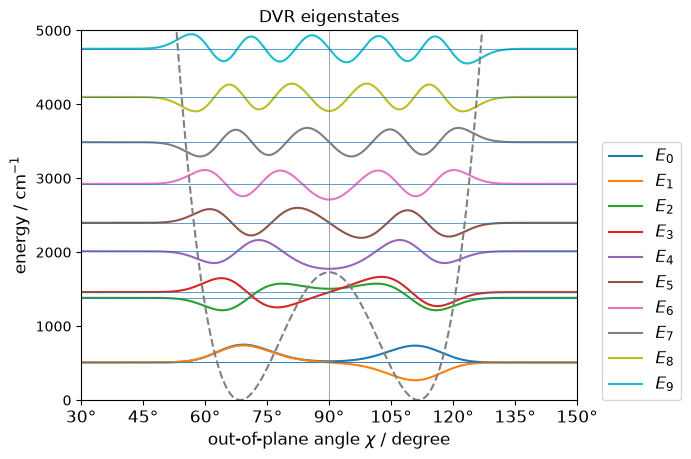

In [3]:
def dvr_1d_sine(a, b, N, K, cs_g, cs_V):

    L = b - a
    chi = a + L * (np.arange(N) + 0.5) / N
    w = L / N
    n = np.arange(1, K + 1)
    arg = np.outer(chi - a, n) * np.pi / L
    X = np.sqrt(2 / L) * np.sin(arg) # chi_n(chi_j)
    dX = np.sqrt(2 / L) * (n * np.pi / L) * np.cos(arg) # chi_n'(chi_j)

    g = cs_g(chi)
    gm14 = g ** -0.25
    dgm14 = -0.25 * cs_g(chi, 1) * g ** -1.25

    U = dgm14[:, None] * X + gm14[:, None] * dX # d/dchi [g^{-1/4} chi_n]
    T = 0.5 * HBar**2 * w * (U.T @ (g[:, None] ** -0.5 * U))
    Vm = w * (X.T @ ((cs_V(chi)[:, None]) * X))
    H = T + Vm
    H = (H + H.T) / 2
    return np.linalg.eigvalsh(H), H

if __name__ == "__main__":
    a = OOP_SCAN[0]
    b = OOP_SCAN[-1]
    N, K = 401, 200
    cs_g = CubicSpline(OOP_SCAN, 1.0 / METRIC)
    cs_V = CubicSpline(OOP_SCAN, POT - POT_EQ)
    E, H = dvr_1d_sine(a, b, N, K, cs_g, cs_V)
    _, C = np.linalg.eigh(H) # get eigenvectors of the Hamiltonian

    E_dvr = E / CmInv
    print(f"First 16 DVR eigenenergies (cm^-1): {np.round(E_dvr[:16], 0)}")

    L = b - a
    w = L / N
    chi_p = np.linspace(a, b, 1000)
    n_b = np.arange(1, K + 1)
    X_p = np.sqrt(2 / L) * np.sin(np.outer(chi_p - a, n_b) * np.pi / L) # Sine basis

    for i, n in enumerate(range(10)):
        psi_t = X_p @ C[:, n]  # amplitude w.r.t. d(phi)
        y = psi_t * 150 + E[n] / CmInv # signed amplitude shows the parity
        plt.plot(np.degrees(chi_p), y, label=f'$E_{{{n}}}$')
        plt.hlines(E[n] / CmInv, np.degrees(a), np.degrees(b), lw=0.5)

    plt.title("DVR eigenstates")
    plt.plot(np.degrees(chi_p), (cs_V(chi_p)) / CmInv, ls='dashed', c='gray')
    plt.axvline(90, c='gray', lw=0.5)
    xticks = np.arange(30, 151, 15)
    plt.xticks(xticks, labels=[f'{int(t)}°' for t in xticks], fontsize=12)
    plt.xlim(np.degrees(a), np.degrees(b))
    plt.ylim(0, 5000)
    plt.legend(loc=(1.05, 0), fontsize=12)
    plt.xlabel(r'out-of-plane angle $\chi$ / degree', fontsize=12)
    plt.ylabel(r'energy / cm$^{-1}$', fontsize=12)
    plt.show()

## Overlap with the initial states

In the SC-IVR calculation, the initial state $|\Psi\rangle$ enters only through the overlap with the coherent states along the trajectories, $\langle \Psi | q_t, p_t \rangle$.

The out-of-plane angle $\chi$ has the topology `"I-"` with the boundaries at $\chi = 0$ and $\pi$. In this system, however, the potential diverges toward the boundaries and the trajectories never approach them, so that the boundary conditions can be ignored and a single Gaussian (topology $\mathbb{R}^1$) is sufficient,

\begin{align*}
\langle \chi | q, p \rangle_{\mathbb{R}^1} = \left( \frac{\gamma}{\pi} \right)^{1/4} \exp \left[ -\frac{\gamma}{2} (\chi - q)^2 + \frac{i}{\hbar} p (\chi - q) \right].
\end{align*}

If the boundary conditions cannot be ignored, the sum over the images should be taken (see Section II E 2 or Appendix H of the paper).

Since the coherent state is a Gaussian, its overlap with various basis functions can be computed easily. The DVR eigenstates are expanded in the sine basis on $[a, b] = [\pi/6, 5\pi/6]$ with $L = b - a$,

\begin{align*}
\Phi_n(\chi) = \sqrt{\frac{2}{L}} \sin \left( k_n (\chi - a) \right), \quad k_n = \frac{n \pi}{L}.
\end{align*}

Extending the integration range to the whole real line, the overlap is obtained analytically,

\begin{align*}
\langle \Phi_n | q, p \rangle = \sqrt{\frac{2}{L}} \left( \frac{\gamma}{\pi} \right)^{1/4} \sqrt{\frac{2\pi}{\gamma}} \frac{1}{2i}
\left[ e^{i k_n (q - a)} e^{-(p/\hbar + k_n)^2 / (2\gamma)} - e^{-i k_n (q - a)} e^{-(p/\hbar - k_n)^2 / (2\gamma)} \right],
\end{align*}

and the overlap with the eigenstate $|E_m\rangle = \sum_n C_{nm} |\Phi_n\rangle$ is $\langle E_m | q, p \rangle = \sum_n C_{nm} \langle \Phi_n | q, p \rangle$.

Since the sine basis vanishes outside $[a, b]$, the extension of the integration range introduces an error when the coherent state extends beyond the boundaries. We verify the analytical overlap against the numerical integration on a fine grid within $[a, b]$. The width parameter $\gamma$ can be chosen arbitrarily (it may affect the convergence), and we set $\gamma = 100$ to make the Gaussian narrow. Note that the same $\gamma$ must be used in the overlap and in the prefactor.

In [4]:
def coherent_state(x, q, p, gamma):
    return (gamma / np.pi) ** 0.25 * np.exp(-0.5 * gamma * (x - q) ** 2 + 1j * p * (x - q) / HBar)

def basis_overlap(n, a, L, q, p, gamma):
    k = n * np.pi / L
    kappa = p / HBar
    pref = np.sqrt(2 / L) * (gamma / np.pi) ** 0.25 * np.sqrt(2 * np.pi / gamma) / 2j
    return pref * (np.exp(1j * k * (q - a) - (kappa + k) ** 2 / (2 * gamma))
                   - np.exp(-1j * k * (q - a) - (kappa - k) ** 2 / (2 * gamma)))

def get_eigen_overlap(posi, mome, gamma, coeff):
    """<E_m|p_t q_t> along the trajectory; coeff = C[:, m]."""
    S = basis_overlap(n_b, a, L, posi[:, 0][:, None], mome[:, 0][:, None], gamma)   # (T, K)
    return S @ coeff

if __name__ == "__main__":
    # fine grid for Riemann sum
    N_fine = 20000
    chi_fine = a + L * (np.arange(N_fine) + 0.5) / N_fine
    w_fine = L / N_fine
    X_fine = np.sqrt(2 / L) * np.sin(np.outer(chi_fine - a, n_b) * np.pi / L) # Sine basis

    gamma = 100.0
    q = np.linspace(OOP_SCAN[0], OOP_SCAN[-1], 50)

    S_grid = w_fine * coherent_state(chi_fine[None, :], q[:, None], 0.0, gamma) @ X_fine # (50, K)
    S_analytical = basis_overlap(n_b, a, L, q[:, None], 0.0, gamma) # (50, K)

    err = np.max(np.abs(S_grid - S_analytical))
    for x, e in zip(q, np.max(np.abs(S_grid - S_analytical), axis=1)):
        print(f"oop (deg) = {x/np.pi * 180:.3f}, max error = {e:.3e}")

oop (deg) = 30.000, max error = 1.774e-01
oop (deg) = 32.449, max error = 1.137e-01
oop (deg) = 34.898, max error = 6.445e-02
oop (deg) = 37.347, max error = 3.192e-02
oop (deg) = 39.796, max error = 1.367e-02
oop (deg) = 42.245, max error = 5.025e-03
oop (deg) = 44.694, max error = 1.574e-03
oop (deg) = 47.143, max error = 4.188e-04
oop (deg) = 49.592, max error = 9.418e-05
oop (deg) = 52.041, max error = 1.787e-05
oop (deg) = 54.490, max error = 2.852e-06
oop (deg) = 56.939, max error = 3.824e-07
oop (deg) = 59.388, max error = 4.304e-08
oop (deg) = 61.837, max error = 4.059e-09
oop (deg) = 64.286, max error = 3.207e-10
oop (deg) = 66.735, max error = 2.120e-11
oop (deg) = 69.184, max error = 1.173e-12
oop (deg) = 71.633, max error = 5.427e-14
oop (deg) = 74.082, max error = 6.217e-15
oop (deg) = 76.531, max error = 6.106e-15
oop (deg) = 78.980, max error = 7.661e-15
oop (deg) = 81.429, max error = 3.664e-15
oop (deg) = 83.878, max error = 4.829e-15
oop (deg) = 86.327, max error = 7.

The error is significant only when the center of the coherent state is close to the boundaries, where the Gaussian (width $1/\sqrt{\gamma} \approx 0.1$ rad) extends beyond $[a, b]$. Within 45-135 degrees, the error is smaller than about $10^{-3}$, and it decreases rapidly toward the center (smaller than $10^{-5}$ within 55-125 degrees). In this tutorial, the eigenstates $E_0$ to $E_9$ are used as the initial states, which are localized within 45-135 degrees, and the trajectories also stay within this range.

In [5]:
def run(posi_sample_list, mome_sample_list, gamma,
        fpath_list, coeff_list,
        dt, n_step, n_fft, symp_err_tol=1e-2):

    assert len(fpath_list) == len(coeff_list[1]), "fpath_list and coeff_list must have the same length"

    # Judge function to check if the point is singular or not
    judge_func = lambda symp_err: np.isfinite(symp_err) & (symp_err < symp_err_tol)

    n_sample = len(mome_sample_list)
    n_ref = len(fpath_list)
    spectra = [0.0] * n_ref
    vari_propagator = make_vari_propagator_implicit(METRIC_FUNC, dt,
                                                    potential_func=POTENTIAL_FUNC, normalize=False)

    t_start = time.perf_counter()
    for i in range(n_sample):
        # Get trajectory
        traj = ImplicitVerlet(posi_sample_list[i], mome_sample_list[i], dt, METRIC_FUNC,
                              potential_func=POTENTIAL_FUNC, normalize=False).run(n_step)
        posi, mome = traj["posi"], traj["mome"]

        # Get variation
        mono_init = np.eye(len(ACTIVE_IDX) * 2)
        mono = propagate_variation_implicit(vari_propagator, posi, mome, traj["mome_half"], mono_init)
        symplectic_error = np.max(np.abs(mono.transpose(0, 2, 1) @ SKEW @ mono - SKEW), axis=(1, 2))

        # Points with large symplectic error are treated as singularities
        valid = judge_func(symplectic_error)

        lag = get_lagrangian(traj["total_energy"], traj["potential_energy"], ener_ref=ENER_EQ)
        action = get_action(lag, dt)
        prefactor = get_prefactor(mono, gamma, valid=valid)
        overlap_sine = get_eigen_overlap(posi, mome, gamma, coeff_list)

        for j in range(n_ref):
            ener_grid, spec = get_ta_spectrum_fft(prefactor, overlap_sine[:, j], action, dt, n_fft, valid=valid)

            spectra[j] += spec

        if i % 10 == 0:
            print(f"{i+1:6d} / {n_sample}, E = {(traj['total_energy'][-1]-ENER_EQ)/CmInv:.1f} cm^-1, "
                  f"max symp error = {np.max(symplectic_error):.3e}, ({time.perf_counter() - t_start:.1f} sec)", flush=True)

    for j in range(n_ref):
        spectra[j] /= n_sample

    for j in range(n_ref):
        np.savez(fpath_list[j], ener_grid=ener_grid, spectrum=spectra[j])

## Execute calculation

The total propagation time is 5 ps (10000 steps of 0.5 fs), and 400 trajectories are sampled up to the kinetic energy of 5000 $\textrm{cm}^{-1}$.

In [6]:
if __name__ == "__main__":
    N_SAMPLE = 400
    K_MAX = 5000.0 # cm^-1

    posi_sample_list = np.repeat([POSI_EQ], N_SAMPLE, axis=0)
    mome_max = np.sqrt(2 * K_MAX * CmInv / METRIC_SPLINE(POSI_EQ))
    # G p^2/2 = K
    mome_sample_list = np.linspace(mome_max / N_SAMPLE, mome_max, N_SAMPLE)[:, None]

    state_list = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
    gamma = np.array([100.0])
    dt = 0.1 * FemtoSec
    n_step = 10000
    n_fft = 2 ** 19
    fpath_list = [f"ammonia_oop_eigen_{m:.0f}_spectra.npz" for m in state_list]
    coeff_list = C[:, state_list]

    run(posi_sample_list, mome_sample_list, gamma,
        fpath_list, coeff_list,
        dt, n_step, n_fft)

     1 / 400, E = 0.0 cm^-1, max symp error = 6.883e-15, (0.6 sec)
    11 / 400, E = 3.8 cm^-1, max symp error = 2.143e-14, (2.9 sec)
    21 / 400, E = 13.8 cm^-1, max symp error = 1.354e-14, (5.2 sec)
    31 / 400, E = 30.0 cm^-1, max symp error = 2.087e-14, (7.5 sec)
    41 / 400, E = 52.5 cm^-1, max symp error = 1.121e-14, (9.8 sec)
    51 / 400, E = 81.3 cm^-1, max symp error = 1.088e-14, (12.2 sec)
    61 / 400, E = 116.3 cm^-1, max symp error = 2.109e-14, (14.5 sec)
    71 / 400, E = 157.5 cm^-1, max symp error = 3.397e-14, (16.9 sec)
    81 / 400, E = 205.0 cm^-1, max symp error = 1.910e-14, (19.2 sec)
    91 / 400, E = 258.8 cm^-1, max symp error = 2.798e-14, (21.5 sec)
   101 / 400, E = 318.8 cm^-1, max symp error = 4.952e-14, (23.9 sec)
   111 / 400, E = 385.0 cm^-1, max symp error = 4.463e-14, (26.2 sec)
   121 / 400, E = 457.6 cm^-1, max symp error = 4.285e-14, (28.3 sec)
   131 / 400, E = 536.3 cm^-1, max symp error = 1.006e-13, (30.4 sec)
   141 / 400, E = 621.3 cm^-1, ma

Peaks (cm^-1) for m = 0: [524.]
Peaks (cm^-1) for m = 1: [524.]
Peaks (cm^-1) for m = 2: [ 527. 1446.]
Peaks (cm^-1) for m = 3: [1447.]
Peaks (cm^-1) for m = 4: [1541. 1951. 2238.]
Peaks (cm^-1) for m = 5: [2395.]
Peaks (cm^-1) for m = 6: [2910.]
Peaks (cm^-1) for m = 7: [3478.]
Peaks (cm^-1) for m = 8: [4091.]
Peaks (cm^-1) for m = 9: [4745.]


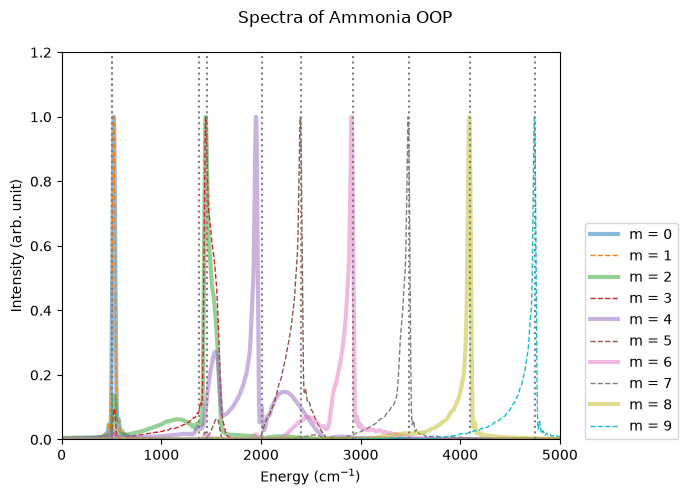

In [11]:
if __name__ == "__main__":
    import matplotlib.pyplot as plt
    from scipy.signal import find_peaks

    fpath_list = [f"ammonia_oop_eigen_{m:.0f}_spectra.npz" for m in state_list]

    fig, ax = plt.subplots(1, 1, figsize=(7, 5), sharex=True)

    dvr_ref = E_dvr[state_list]

    for i, fpath in enumerate(fpath_list):
        data = np.load(fpath)
        ener_grid = data["ener_grid"] / CmInv
        spectrum = data["spectrum"]
        spectrum /= np.max(spectrum[ener_grid <= 5000])
        peaks, _ = find_peaks(spectrum, height=0.1, prominence=0.1)
        peaks = peaks[ener_grid[peaks] <= 5000]
        print(f"Peaks (cm^-1) for m = {state_list[i]:.0f}: {np.round(ener_grid[peaks], 0)}")
 
        plt.plot(ener_grid, spectrum, label=f"m = {state_list[i]:.0f}",
                     linewidth= 3 if i % 2 == 0 else 1, alpha= 0.5 if i % 2 == 0 else 1,
                     linestyle= "-" if i % 2 == 0 else "--")

    plt.suptitle("Spectra of Ammonia OOP")
    plt.xlim(0, 5000)
    plt.ylim(0, 1.2)
    plt.vlines(dvr_ref, 0, 1.2, color='gray', linestyle=":")
    plt.xlabel("Energy (cm$^{-1}$)")
    plt.ylabel("Intensity (arb. unit)")
    plt.legend(loc=(1.05, 0))
    plt.tight_layout()
    plt.show()

The spectra obtained with the DVR eigenstates $|E_m\rangle$ as the initial states are compared with the DVR eigenvalues and with the peaks obtained with the coherent states in the tutorial *Pyramidal Inversion Spectrum of Ammonia* (all in $\textrm{cm}^{-1}$). For $1^{+}$ and $2^{+}$, the additional peaks are shown in parentheses.

| Level | $E$ (DVR) | $E$ (SC-IVR, eigenstate) | $E$ (SC-IVR, coherent state) |
|---|---|---|---|
| $0^{+}$ / $0^{-}$ | 508 / 510 | 524 / 524 | 520 |
| $1^{+}$ / $1^{-}$ | 1383 / 1460 | 1446 (527) / 1447 | 1445 |
| $2^{+}$ / $2^{-}$ | 2013 / 2397 | 1951 (1541, 2238) / 2395 | 1950 / 2396 |
| $3^{+}$ / $3^{-}$ | 2924 / 3489 | 2910 / 3478 | 2912 / 3480 |
| $4^{+}$ / $4^{-}$ | 4101 / 4752 | 4091 / 4745 | 4093 / 4744 |

- **Peak positions**: The peaks obtained with the eigenstates agree with those obtained with the coherent states within a few $\textrm{cm}^{-1}$. The peak positions are determined by the semiclassical propagation itself, and the initial state only selects which levels appear and with what intensities.

- **Levels well above the barrier**: Each eigenstate ($m = 5$ to $9$) gives a single sharp peak at the corresponding level, and the individual levels are extracted without ambiguity in the assignment.

- **Tunneling doublets**: Both $0^{+}$ and $0^{-}$ give a single peak at the same position, and so do $1^{+}$ and $1^{-}$. Even with the exact eigenstates as the initial states, the semiclassical propagation with classical trajectories does not distinguish the two levels of each doublet.

- **Levels near the barrier top**: For $1^{+}$, a peak also appears at the ground level (527 $\textrm{cm}^{-1}$), although the exact eigenstates are orthogonal to each other. For $2^{+}$, which lies just above the barrier top, the main peak is shifted by about $-60$ $\textrm{cm}^{-1}$ and the intensity leaks to other energies (1541 and 2238 $\textrm{cm}^{-1}$). The semiclassical approximation breaks down most severely near the barrier top.

In summary, any initial state can be used in SC-IVR by defining the overlap $\langle \Psi | q_t, p_t \rangle$, while the trajectories, prefactors and actions are shared among all the initial states.

More generally, PySCIVR does not bundle the SC-IVR calculation into a single function by design. The actions, prefactors, overlaps and spectra are computed by separate functions, so that each component can be replaced independently. For example, the prefactor can be computed by other methods: various approximations of the prefactor have been proposed to avoid the instability caused by chaotic trajectories and to reduce the computational cost.[1] Likewise, the trajectories are not tied to the calculation of spectra, and other properties can be computed from the same set of trajectories by combining the components in different ways.

**References** 

[1] G. Di Liberto and M. Ceotto, “The importance of the pre-exponential factor in semiclassical molecular dynamics,” *J. of Chem Phys* **145** (2016)